# GPX6 genome-wide — where the variant sits in the GEA

**The variant:** Chr4:7,011,705, a **1,164 bp deletion 330 bp upstream of GPX6**
(AT4G11600, phospholipid hydroperoxide glutathione peroxidase, mitochondrial), 27 founder carriers,
MAF 0.118. Bonferroni-significant on **6 axes / 5 climate clusters**: pc1, bio11, bio6, bio1, bio3,
bio12 (all but bio12 cold-temperature axes). Full chain:
`genes/convergence/results/audit/GPX6_audit.txt`. Other axes build on demand.

Those numbers are from the **pre-floor scan**. The deletion event is called in only 78 of 231
founders (0.34), below the production call-rate floor of 0.50, so **it is not tested in
`tile_cr50`** on any axis -- the figures below place it by position only.

**Layout** (as in `peak_alignment_manhattan_gea.ipynb`): **SVs point up, SNPs point down** on one
genome axis; dashed lines are each class's own Bonferroni (0.05 / n records of that class); SNPs with
p > 0.01 are not drawn. Open red circles = SV peaks with no significant SNP within
10 kb. **The GPX6 variant is the filled red diamond**, with a vertical guide through
both halves.

The `up` class here is **sv**, the scan this variant's record actually lives in.

Per axis: the genome-wide figure, then a ±250 kb zoom on the locus, where the SNPs that track
the same haplotype are visible.

Raw LFMM p, gen9, production `tile_cr50` (MAF > 0.05, founder call rate ≥ 0.50; SVs as Truvari
events), **no inflation correction** — these are a candidate net, not a calibrated test.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def _tree_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.basename(d) == "grenenet_selection" and os.path.exists(os.path.join(d, "lib.py")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no grenenet_selection root above " + os.getcwd())
GS = _tree_root()
sys.path.insert(0, GS); sys.path.insert(0, f"{GS}/blocks"); sys.path.insert(0, f"{GS}/genes/convergence")
sys.path.insert(0, f"{GS}/genes/convergence/v2")
import lib, blocks_tiling as bt, plot_theme as TH, units as UN
TH.apply()
# production GEA: MAF >= 0.05 AND founder call rate >= 0.50; sv/nonsnp rows are Truvari events (`unit`)
GEAIN = f"{GS}/r2_gea_nonsnp/phase1_replication/results/multiaxis/tile_cr50"
PLOTS = f"{GS}/notebooks/plots"; os.makedirs(PLOTS, exist_ok=True)
WINDOW, ZOOM_KB, SNP_FLOOR = 10000, 250, 2.0

# the candidate
GENE, SYM = "AT4G11600", "GPX6"
VCHROM, VPOS, VSIZE = "Chr4", 7011705, 1164
GSTART, GEND = 7009769, 7011375
UPCLS, UPLABEL, KIND = "sv", "SV", "1,164 bp promoter deletion"
UNIT = 1631335
_ui = UN.info([UNIT]).iloc[0]
assert _ui.chrom == VCHROM and int(_ui.pos) == VPOS, "unit id does not match the candidate position"
UCALLED, UMEMBERS = int(_ui.n_called), int(_ui.n_members)
UNTESTED = (f"not tested in tile_cr50: called in {UCALLED}/231 founders, below the 0.50 floor"
            if UCALLED < 116 else "not in tile_cr50 (call rate passes; check MAF)")

CHROM_LEN = {"Chr1": 30427671, "Chr2": 19698289, "Chr3": 23459830, "Chr4": 18585056, "Chr5": 26975502}
GAP = 3_500_000
CH = list(CHROM_LEN); OFF = {}; _a = 0
for _c in CH: OFF[_c] = _a; _a += CHROM_LEN[_c] + GAP
GENOME = _a - GAP
VX = OFF[VCHROM] + VPOS

SVCOL, SVLIGHT = "#3F7D4A", "#8DB896"
SNPCOL = ("#8A8A8A", "#C4C4C4")
AXISNAME = {"pc1": "climate PC1", "bio1": "annual mean temperature",
            "bio3": "isothermality", "bio6": "min temperature of coldest month",
            "bio11": "mean temperature of coldest quarter", "bio12": "annual precipitation",
            "bio15": "precipitation seasonality", "bio14": "precipitation of driest month",
            "bio17": "precipitation of driest quarter", "bio8": "mean temp of wettest quarter",
            "bio9": "mean temp of driest quarter"}

def load(cls, axis):
    f = f"{GEAIN}/lfmm_{cls}_gen9_{axis}.csv"
    hdr = open(f).readline().rstrip("\n").split(",")           # snp tables carry no `unit`
    d = pd.read_csv(f, usecols=["chrom", "pos", "MAF", "pval"] + (["unit"] if "unit" in hdr else []))
    d = d[d.MAF > 0.05].copy()
    d["block"] = bt.assign_tiling(d.chrom.to_numpy(), d.pos.to_numpy(), r2=0.9)
    d["nlp"] = -np.log10(d.pval.clip(lower=1e-300))
    d["x"] = d.chrom.map(OFF) + d.pos
    d.attrs["bar"] = -np.log10(0.05 / len(d))
    return d

def sv_snp_peaks(D, window):
    # significant blocks per class -> record-span extents -> merged within `window` -> SV peaks,
    # flagged sv_only when the peak carries no significant SNP (the rule of the main notebook)
    rows = []
    for cls in [UPCLS, "snp"]:
        d = D[cls]; lead = d.groupby("block").nlp.max(); sb = set(lead.index[lead > d.attrs["bar"]])
        e = d[d.block.isin(sb)].groupby("block").agg(chrom=("chrom", "first"), start=("pos", "min"),
                                                     end=("pos", "max")).reset_index()
        e["cls"] = cls; rows.append(e)
    t = pd.concat(rows).sort_values(["chrom", "start"])
    lid, cur, pch, pend = [], -1, None, -np.inf
    for r in t.itertuples():
        if r.chrom != pch or r.start - pend > window: cur += 1; pend = r.end
        else: pend = max(pend, r.end)
        pch = r.chrom; lid.append(cur)
    t["locus"] = lid
    out = []
    for lid, g in t.groupby("locus"):
        ch, lo, hi = g.chrom.iloc[0], g.start.min(), g.end.max()
        if UPCLS not in set(g.cls): continue
        q = D[UPCLS][(D[UPCLS].chrom == ch) & D[UPCLS].pos.between(lo, hi)]
        b = q.loc[q.nlp.idxmax()]
        out.append(dict(chrom=ch, start=lo, end=hi, pos=int(b.pos), x=int(b.x), nlp=float(b.nlp),
                        sv_only="snp" not in set(g.cls)))
    return pd.DataFrame(out)

def cand_record(D):
    # the variant's own -log10 p per class on this axis, looked up by its unit id (an SV class row
    # is an EVENT at its representative allele, so a position/allele lookup can miss or mis-hit);
    # NaN if the unit is not in tile_cr50
    out = {}
    for cls in [UPCLS, "nonsnp"]:
        q = D[cls][D[cls].unit == UNIT] if "unit" in D[cls] else D[cls].iloc[:0]
        out[cls] = float(q.nlp.max()) if len(q) else np.nan
    return out

print("loaded helpers ·", SYM, f"{VCHROM}:{VPOS:,} ({KIND}) · unit {UNIT}: {UMEMBERS} member record(s), "
      f"called in {UCALLED}/231 founders")

loaded helpers · GPX6 Chr4:7,011,705 (1,164 bp promoter deletion) · unit 1631335: 12 member record(s), called in 78/231 founders


In [2]:
def manh(ax, d, cols, sign=1, s=1.6, alt=True):
    for i, ch in enumerate(CH):
        k = d[d.chrom == ch]
        if len(k):
            ax.scatter(k.x, sign * k.nlp, s=s, c=cols[i % 2] if alt else cols[0],
                       linewidths=0, rasterized=True, zorder=1)

def cand_mark(ax, nlp_sv, shift, lo, hi, label=True):
    # vertical guide through both halves + a filled diamond on the deletion's SV point
    if not (lo <= VX <= hi): return
    ax.axvline(VX, color=TH.ACCENT, lw=1.0, ls=(0, (4, 3)), alpha=0.55, zorder=2)
    if np.isfinite(nlp_sv):
        ax.scatter([VX], [nlp_sv], marker="D", s=70, color=TH.ACCENT, edgecolor="white",
                   linewidth=0.8, zorder=7, clip_on=False)
    if label:
        ax.annotate(f"{SYM}\n{VCHROM}:{VPOS:,}", (VX, ax.get_ylim()[1]), xytext=(6, -4),
                    textcoords="offset points", ha="left", va="top", fontsize=8.5, color=TH.ACCENT)

def miami(axis, D, P, lo=0, hi=None, zoom=False, fname=None):
    hi = GENOME if hi is None else hi
    fig, ax = plt.subplots(figsize=(17, 6.2 if not zoom else 5.4))
    sv = D[UPCLS]; snp = D["snp"]
    inx = lambda d: d[(d.x >= lo) & (d.x <= hi)]
    SHIFT = SNP_FLOOR - 0.5 if not zoom else 0.0        # the p>0.01 cut only applies genome-wide
    s = inx(snp) if zoom else inx(snp[snp.nlp >= SNP_FLOOR]).assign(nlp=lambda d: d.nlp - SHIFT)
    manh(ax, inx(sv), (SVCOL, SVLIGHT), +1, s=3 if zoom else 1.6, alt=not zoom)
    manh(ax, s, SNPCOL, -1, s=3 if zoom else 1.6, alt=not zoom)
    ax.axhline(sv.attrs["bar"], ls="--", lw=0.8, color=TH.MUTED)
    ax.axhline(-(snp.attrs["bar"] - SHIFT), ls="--", lw=0.8, color=TH.MUTED)
    ax.axhline(0, color=TH.AXIS, lw=0.8)
    if not zoom:
        q = P[P.sv_only]
        ax.scatter(q.x, q.nlp, s=110, facecolor="none", edgecolor="#B03A4B", linewidth=1.3,
                   alpha=0.55, zorder=5, clip_on=False)
    top = max(inx(sv).nlp.max(), 1) * 1.18
    bot = max(inx(snp).nlp.max() - SHIFT, 1) * 1.10
    ax.set_ylim(-bot, top)
    up = np.arange(0, top, 2 if zoom else 4)
    dn = np.arange(2 if zoom else 4, inx(snp).nlp.max() + 1, 2 if zoom else 4)
    ax.set_yticks(np.r_[-(dn[::-1] - SHIFT), up])
    ax.set_yticklabels([f"{v:g}" for v in dn[::-1]] + [f"{v:g}" for v in up])
    ax.set_ylabel(f"−log10 p\nSNP ↓        {UPLABEL} ↑")
    TH.grid_only(ax, "y")
    cand_mark(ax, cand_record(D)[UPCLS], SHIFT, lo, hi)
    if zoom:
        ax.axvspan(OFF[VCHROM] + GSTART, OFF[VCHROM] + GEND, color=TH.ACCENT, alpha=0.10, lw=0, zorder=0)
        # ticks on round 50 kb positions, not on the window edges (which round to the wrong label)
        step = 50_000
        t0 = int(np.ceil((lo - OFF[VCHROM]) / step) * step)
        tk = np.arange(t0, hi - OFF[VCHROM], step)
        ax.set_xticks(OFF[VCHROM] + tk); ax.set_xticklabels([f"{t/1e6:.2f}" for t in tk], fontsize=8.5)
        ax.set_xlabel(f"{VCHROM} position (Mb)")
        ax.set_xlim(lo, hi)
    else:
        pad = 0.015 * GENOME
        ax.set_xlim(-pad, GENOME + pad)
        ax.set_xticks([OFF[c] + CHROM_LEN[c] / 2 for c in CH]); ax.set_xticklabels(CH, fontsize=11)
        ax.tick_params(axis="x", length=0)
    h = ([Line2D([], [], marker="D", ls="", color=TH.ACCENT, markersize=8, label=f"{SYM} {KIND}")]
         if np.isfinite(cand_record(D)[UPCLS]) else
         [Line2D([], [], ls=(0, (4, 3)), color=TH.ACCENT, label=f"{SYM} {KIND} ({UNTESTED})")])
    if not zoom:
        h.append(Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="#B03A4B",
                        markeredgewidth=1.3, markersize=10, alpha=0.7,
                        label=f"new {UPLABEL} peak"))
    h.append(Line2D([], [], ls="--", color=TH.MUTED, label="Bonferroni"))
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=len(h), fontsize=9.5)
    if fname:
        for ext in ["png", "pdf"]:
            plt.savefig(f"{PLOTS}/{fname}.{ext}", dpi=200, bbox_inches="tight", pad_inches=0.25)
    plt.show()

def run(axis):
    D = {c: load(c, axis) for c in ["snp", UPCLS]}
    if "nonsnp" not in D:
        D["nonsnp"] = load("nonsnp", axis)
    P = sv_snp_peaks(D, WINDOW)
    g = cand_record(D)
    if np.isfinite(g[UPCLS]):
        rank = int((D[UPCLS].nlp > g[UPCLS]).sum() + 1)
        print(f"{axis} ({AXISNAME.get(axis, '')}): {SYM} {KIND} −log10 p = "
              f"{g[UPCLS]:.2f} ({UPCLS}), {g['nonsnp']:.2f} (non-SNP pool); {UPCLS} bar "
              f"{D[UPCLS].attrs['bar']:.2f}, SNP bar {D['snp'].attrs['bar']:.2f}; rank {rank} of "
              f"{len(D[UPCLS]):,} {UPCLS} rows genome-wide")
    else:
        print(f"{axis} ({AXISNAME.get(axis, '')}): {SYM} {KIND} (unit {UNIT}) is {UNTESTED}; "
              f"{UPCLS} bar {D[UPCLS].attrs['bar']:.2f}, SNP bar {D['snp'].attrs['bar']:.2f}")
    print(f"  {len(P)} {UPLABEL} peaks genome-wide, {P.sv_only.sum()} with no significant SNP "
          f"within {WINDOW // 1000} kb")
    miami(axis, D, P, fname=f"gpx6_miami_{axis}")
    lo, hi = VX - ZOOM_KB * 1000, VX + ZOOM_KB * 1000
    miami(axis, D, P, lo, hi, zoom=True, fname=f"gpx6_zoom_{axis}")
    return D, P

## pc1

pc1 (climate PC1): GPX6 1,164 bp promoter deletion (unit 1631335) is not tested in tile_cr50: called in 78/231 founders, below the 0.50 floor; sv bar 5.60, SNP bar 7.55
  15 SV peaks genome-wide, 13 with no significant SNP within 10 kb


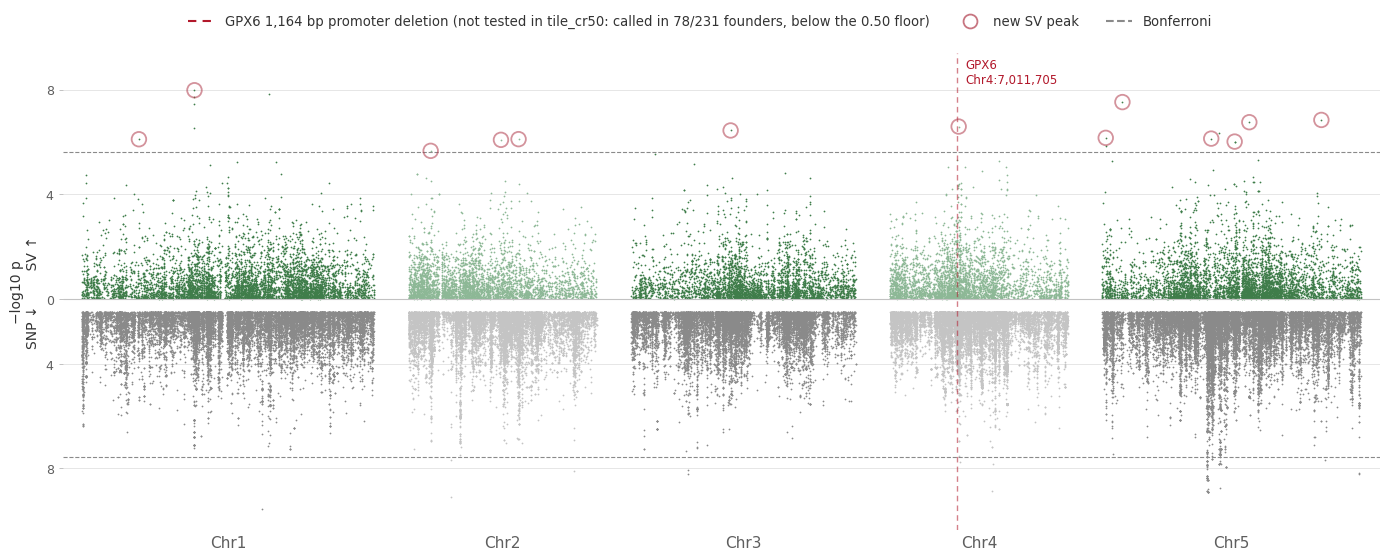

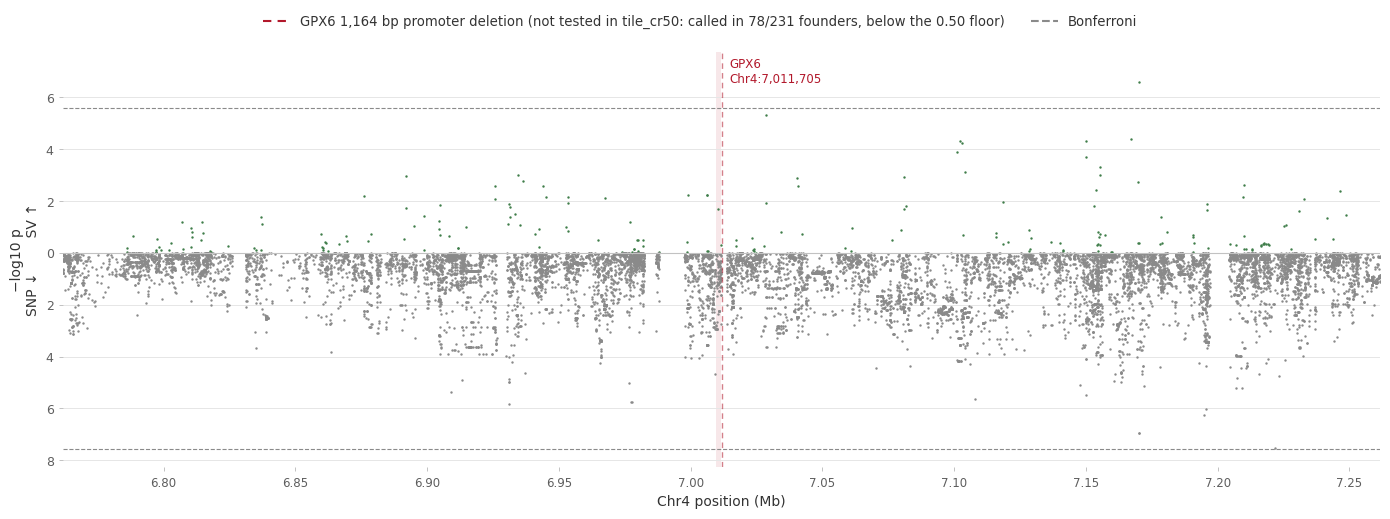

In [3]:
D, P = run("pc1")

### pc1 — zoom on the locus, with linkage to the deletion

A ±120 kb LocusZoom view of the same pc1 scan, asking whether the SNP signal here is the deletion seen
through linkage, and whether a SNP-only analysis would have reached GPX6.

**Which unit the deletion is.** The panel decomposes Chr4:7,011,705 into near-identical deletion
alleles (REF 1,225 bp → ALT 50–63 bp), one record per assembly path, all called in the same **78 of
231 founders** (call rate 0.34). Truvari collapses them into **one event** (`unit`, member count and
union carriers printed below), and the production GEA tests events, not alleles. At 78/231 the event
falls below the **0.50 call-rate floor**, so it is **not tested in `tile_cr50`** and has no p-value
here: panel a places it by position only. (The pre-floor scan tested a single 13-carrier member
allele, store row 1517046; that allele-level view is superseded.)

**Linkage.** Colours are **founder r²** — classical LD between carrier vectors, over founders called
at both. The deletion's vector is the **event's union** over its member records (carrier = carries
any member; called = any member called), the same unit the GEA and the burden work use. For this
variant that is at most 78 of 231 founders, so it is real LD measured on a third of the panel. SNPs
need ≥ 40 shared called founders and MAF ≥ 0.02 to be drawn. The neighbouring SVs are `tile_cr50`
events too, each taken as its own union vector and matched by `unit` id, never by allele key. As a
cross-check the printed table also carries **pool-frequency r²** (correlation of gen-9 frequencies
across the 352 pools, the scale the GEA itself runs on; the event's frequency is the sum over its
members, as the event GEA builds it).

**(a)** −log10 p on pc1 for every Chr4 row in the window: SNPs as circles, **SV events (> 50 bp,
indels excluded) as diamonds**, both coloured by founder r² to the deletion event. The GPX6 deletion
is the red diamond (open, on the axis, when untested). Dashed lines are each class's own Bonferroni
(0.05 / n rows of that class in `tile_cr50`; values printed).
**(b)** every gene in the window as a simple block, labelled by **UniProt/TAIR symbol** where one
exists and by AGI id otherwise (annotation from `annotate_genes_tair_uniprot.py`, cached in
`genes/convergence/results/gpx6_window_gene_annotation.csv`; the AGI id for every gene is printed
under the figure), with the deletion's 1,164 bp span below. GPX6 in red.

Bonferroni on pc1: SNP 0.05/1,790,024 (-log10 7.55), SV 0.05/20,134 events (-log10 5.60)
GPX6 deletion event (unit 1631335) on pc1: not tested in tile_cr50: called in 78/231 founders, below the 0.50 floor -- placed by position only


deletion event unit 1631335: 12 member records (carriers each: [13, 4, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1]); union 28 carriers, called in 78/231


SV events in the window: 91; founder r2 computable for 91; GPX6 event among them: False


57 genes in the window
SVs clearing the SV Bonferroni (5.60) in the window: 0


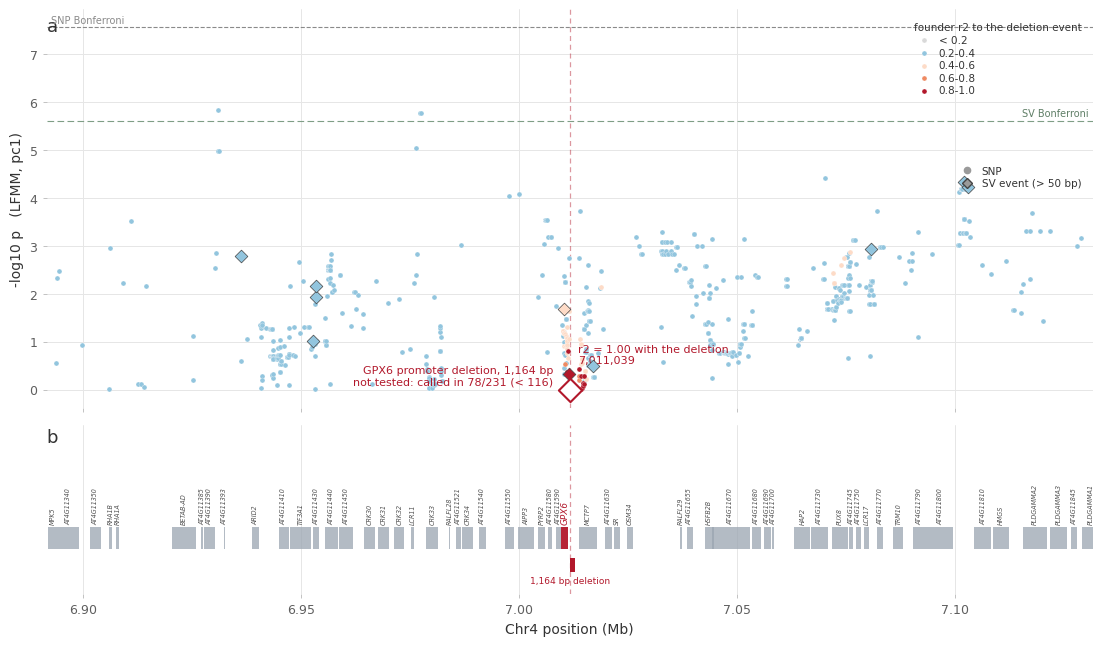


genes in the window (label -> AGI -> UniProt protein name):
  MPK5         AT4G11330  Mitogen-activated protein kinase 5 (AtMPK5) (MAP kinase 5) (EC 2.7.11.24)
  AT4G11340    AT4G11340  Disease resistance protein (TIR-NBS-LRR class) family
  AT4G11350    AT4G11350  Transferring glycosyl group transferase (DUF604)
  RHA1B        AT4G11360  E3 ubiquitin-protein ligase RHA1B (EC 2.3.2.27) (RING-H2 finger A1b) (RING-H2 zinc
  RHA1A        AT4G11370  Probable E3 ubiquitin-protein ligase RHA1A (EC 2.3.2.27) (RING-H2 finger A1a) (RIN
  BETAB-AD     AT4G11380  Beta-adaptin-like protein B (At-bB-Ad) (At-betaB-Ad) (AP complex subunit beta-B) (
  AT4G11385    AT4G11385  Uncharacterized protein
  AT4G11390    AT4G11390  Cysteine/Histidine-rich C1 domain family protein
  AT4G11393    AT4G11393  Putative defensin-like protein 202
  ARID2        AT4G11400  AT-rich interactive domain-containing protein 2 (ARID domain-containing protein 2)
  AT4G11410    AT4G11410  NAD(P)-binding Rossmann-fold superfa

In [4]:

import scipy.sparse as sp
from matplotlib.patches import Rectangle
HALF, AXIS_LD = 120_000, "pc1"
LDBIN = [(0.8, "#B2182B", "0.8-1.0"), (0.6, "#EF8A62", "0.6-0.8"), (0.4, "#FDDBC7", "0.4-0.6"),
         (0.2, "#92C5DE", "0.2-0.4"), (-1, "#D9D9D9", "< 0.2")]
PMDIR = f"{lib.GEA}/common/results/pool_matrices"

_sa = pd.read_csv(f"{GEAIN}/lfmm_snp_gen9_{AXIS_LD}.csv", usecols=["chrom", "pos", "MAF", "pval"])
_sa = _sa[_sa.MAF > 0.05]
BAR_SNP = np.log10(len(_sa) / 0.05)
_s4 = _sa[_sa.chrom == "Chr4"].copy(); _s4["nlp"] = -np.log10(_s4.pval.clip(lower=1e-300))
_sv = pd.read_csv(f"{GEAIN}/lfmm_sv_gen9_{AXIS_LD}.csv",            # one row per SV EVENT
                  usecols=["chrom", "pos", "ref_len", "alt_len", "MAF", "pval", "unit", "dlen"])
_sv = _sv[_sv.MAF > 0.05].copy(); _sv["nlp"] = -np.log10(_sv.pval.clip(lower=1e-300))
BAR_SV = np.log10(len(_sv) / 0.05)
_dq = _sv[_sv.unit == UNIT]
DEL_NLP = float(_dq.nlp.iloc[0]) if len(_dq) else np.nan
print(f"Bonferroni on {AXIS_LD}: SNP 0.05/{len(_sa):,} (-log10 {BAR_SNP:.2f}), "
      f"SV 0.05/{len(_sv):,} events (-log10 {BAR_SV:.2f})")
print(f"{SYM} deletion event (unit {UNIT}) on {AXIS_LD}: " +
      (f"-log10 p = {DEL_NLP:.2f}" if len(_dq) else UNTESTED + " -- placed by position only"))
LEAD = int(_s4.loc[_s4.nlp.idxmax(), "pos"]); LEAD_NLP = float(_s4.nlp.max())

_B = f"{lib.PROJ}/panel/arch3/chr4/var_pa_231_arch3_chr4"
_mt = np.load(f"{_B}.meta.npz", allow_pickle=True)
_pp = _mt["pos"].astype(np.int64); _rl = _mt["ref_len"].astype(np.int64); _al = _mt["alt_len"].astype(np.int64)
_PA = sp.load_npz(f"{_B}.var_pa.npz").tocsc(); _CA = sp.load_npz(f"{_B}.var_called.npz").tocsc()
# the deletion as a Truvari EVENT: carrier = carries any member record, called = any member called
_fd, _ec, _el = UN.carrier_matrix([UNIT])
assert list(_mt["founders"].astype(str)) == _fd, "founder order differs between Chr4 panel and units"
gd, cd = _ec[:, 0], _el[:, 0]
_mem = UN.member_rows(UNIT)
_mc = UN.panel_cols(_mem)[1]
_nper = np.asarray((_PA[:, _mc] > 0).sum(0)).ravel()
print(f"deletion event unit {UNIT}: {_mem.size} member records (carriers each: {sorted(_nper.tolist(), reverse=True)}); "
      f"union {int(gd.sum())} carriers, called in {int(cd.sum())}/231")
_issnp = (_rl == 1) & (_al == 1)
_wj = np.where(_issnp & (_pp > VPOS - HALF) & (_pp < VPOS + HALF))[0]
_PAs = (_PA[:, _wj] > 0).toarray(); _CAs = (_CA[:, _wj] > 0).toarray()
_rows = []
for _k in range(len(_wj)):
    _m = cd & _CAs[:, _k]
    if _m.sum() < 40: continue
    _y = _PAs[_m, _k].astype(float); _x = gd[_m].astype(float); _f = _y.mean()
    if _x.std() == 0 or _y.std() == 0 or min(_f, 1 - _f) < 0.02: continue
    _rows.append((int(_pp[_wj[_k]]), float(np.corrcoef(_x, _y)[0, 1] ** 2)))
FD = pd.DataFrame(_rows, columns=["pos", "r2"]).groupby("pos", as_index=False).r2.max()
# neighbouring SV EVENTS from tile_cr50, each as its own union carrier vector, matched by unit id
SVW = _sv[(_sv.chrom == "Chr4") & (_sv.pos > VPOS - HALF) & (_sv.pos < VPOS + HALF)].copy()
_, _wc, _wl = UN.carrier_matrix(SVW.unit.astype(int).tolist())
_r2sv = []
for _j in range(len(SVW)):
    _m = cd & _wl[:, _j]
    _x = gd[_m].astype(float); _y = _wc[_m, _j].astype(float)
    _r2sv.append(float(np.corrcoef(_x, _y)[0, 1] ** 2) if (_m.sum() >= 40 and _x.std() > 0 and _y.std() > 0) else np.nan)
SVW["r2"] = _r2sv; SVW["carriers"] = _wc.sum(0)
SVW["is_target"] = SVW.unit == UNIT
print(f"SV events in the window: {len(SVW)}; founder r2 computable for {SVW.r2.notna().sum()}; "
      f"GPX6 event among them: {bool(SVW.is_target.any())}")
_IN = np.load(f"{lib.AF_STORE}/index_snp.npz", allow_pickle=True)
_As = np.load(f"{PMDIR}/pool_gen9_snp_af.npy", mmap_mode="r")
# the event's pool frequency = sum over its member records, capped at 1 (as event_gea/build_event_matrix.py)
_dv = np.minimum(np.asarray(np.load(f"{PMDIR}/pool_gen9_nonsnp_af.npy", mmap_mode="r")[:, np.sort(_mem)],
                            dtype=float).sum(1), 1.0)
_sel = np.where((_IN["chrom"] == "Chr4") & (_IN["pos"] > VPOS - HALF) & (_IN["pos"] < VPOS + HALF))[0]
_V = np.asarray(_As[:, _sel], dtype=float); _ok = np.isfinite(_dv)
_Vc = _V[_ok] - _V[_ok].mean(0); _dc = _dv[_ok] - _dv[_ok].mean()
_den = np.sqrt((_Vc ** 2).sum(0) * (_dc ** 2).sum())
_rp = np.divide((_Vc * _dc[:, None]).sum(0), _den, out=np.zeros(len(_sel)), where=_den > 0)
PD = pd.DataFrame(dict(pos=_IN["pos"][_sel], r2_pool=_rp ** 2)).groupby("pos", as_index=False).r2_pool.max()
M = (_s4[(_s4.pos > VPOS - HALF) & (_s4.pos < VPOS + HALF)]
     .merge(FD, on="pos", how="left").merge(PD, on="pos", how="left"))
M["r2"] = M.r2.fillna(-1)

LO, HI = VPOS - HALF, VPOS + HALF
# gene symbols: TAIR GO + UniProt, via r2_gea_nonsnp/phase1_replication/annotate_genes_tair_uniprot.py
#   $PY annotate_genes_tair_uniprot.py --genes-from <window genes> --out results/gpx6_window_gene_annotation.csv
_ann = pd.read_csv(f"{GS}/genes/convergence/results/gpx6_window_gene_annotation.csv")
SYMOF = dict(zip(_ann.gene, _ann.symbol.fillna("")))
PROTOF = dict(zip(_ann.gene, _ann.protein_name.fillna("")))
_label = lambda g: (SYMOF.get(g) or g) if (SYMOF.get(g) or g) != g else g
_G = lib.load_genes()
_g = _G[(_G.chrom == "Chr4") & (_G.end >= LO) & (_G.start <= HI)].sort_values("start")
print(f"{len(_g)} genes in the window")
# the SVs in this window that clear the SV Bonferroni on this axis, with the gene each sits in or
# nearest to (promoter = within 2 kb upstream of the TSS, strand-aware)
_gg = _g.copy(); _gg["tss"] = np.where(_gg.strand == "+", _gg.start, _gg.end)
def _target(p, e):
    _b = _gg[(_gg.start <= e) & (_gg.end >= p)]
    if len(_b):
        return _b.iloc[0].gene, "in gene"
    _u = np.where(_gg.strand == "+", _gg.tss - e, p - _gg.tss)
    _pr = _gg[(_u > 0) & (_u <= 2000)]
    if len(_pr):
        return _pr.iloc[int(np.argmin(_u[(_u > 0) & (_u <= 2000)]))].gene, "promoter"
    _d = np.minimum((_gg.start - e).abs(), (_gg.end - p).abs())
    return _gg.iloc[int(np.argmin(_d))].gene, "nearest"
SVSIG = SVW[SVW.nlp >= BAR_SV].copy()
SVSIG["end"] = SVSIG.pos + np.maximum(SVSIG.ref_len - 1, 0)
_tp = [_target(r.pos, r.end) for r in SVSIG.itertuples()]          # (empty-safe)
SVSIG["target_gene"] = [t[0] for t in _tp]; SVSIG["placement"] = [t[1] for t in _tp]
SVSIG["sym"] = [SYM if t == GENE else (SYMOF.get(t) or t) for t in SVSIG.target_gene]
SVSIG["size_lab"] = [f"{d:+,} bp".replace("+", "+").replace("-", "\u2212") for d in SVSIG.dlen]
print(f"SVs clearing the SV Bonferroni ({BAR_SV:.2f}) in the window: {len(SVSIG)}")

def draw_zoom(fname, mark_candidates=False):
    fig = plt.figure(figsize=(13.5, 7.6))
    _gs = fig.add_gridspec(2, 1, height_ratios=[2.35, 1.0], hspace=0.06)
    XL = (LO / 1e6, HI / 1e6); _mb = lambda p: np.asarray(p) / 1e6

    a = fig.add_subplot(_gs[0]); TH.grid_only(a); TH.panel(a, "a")
    for _lo, _col, _lab in LDBIN[::-1]:
        _k = M[(M.r2 > _lo) & (M.r2 <= (1.01 if _lo == 0.8 else _lo + 0.2))]
        a.scatter(_mb(_k.pos), _k.nlp, s=13, c=_col, linewidths=0.2, edgecolor="white",
                  zorder=3 if _lo >= 0.4 else 2, label=_lab)
    a.axhline(BAR_SNP, ls="--", lw=0.8, color=TH.MUTED)
    a.annotate("SNP Bonferroni", (XL[0], BAR_SNP), xytext=(3, 3), textcoords="offset points", fontsize=7, color=TH.MUTED)
    _sother = SVW[~SVW.is_target]
    for _lo, _col, _lab in LDBIN[::-1]:
        _k = _sother[(_sother.r2.fillna(-1) > _lo) & (_sother.r2.fillna(-1) <= (1.01 if _lo == 0.8 else _lo + 0.2))]
        a.scatter(_mb(_k.pos), _k.nlp, s=42, c=_col, marker="D", linewidths=0.5, edgecolor="#444444", zorder=5)
    a.axhline(BAR_SV, ls=(0, (6, 3)), lw=0.8, color="#7F9E86")
    a.annotate("SV Bonferroni", (XL[1], BAR_SV), xytext=(-3, 3), textcoords="offset points",
               fontsize=7, color="#5F7E66", ha="right")
    if np.isfinite(DEL_NLP):
        a.scatter([VPOS / 1e6], [DEL_NLP], marker="D", s=140, color=TH.ACCENT, edgecolor="white", linewidth=1.1, zorder=7)
        a.annotate(f"{SYM} promoter deletion\n{VSIZE:,} bp, -log10 p = {DEL_NLP:.2f}", (VPOS / 1e6, DEL_NLP),
                   xytext=(9, -2), textcoords="offset points", fontsize=8, color=TH.ACCENT, va="top")
    else:                              # not in tile_cr50: placed by position, no p-value to plot
        a.scatter([VPOS / 1e6], [0], marker="D", s=140, facecolor="white", edgecolor=TH.ACCENT, linewidth=1.5,
                  zorder=7, clip_on=False)
        a.annotate(f"{SYM} promoter deletion, {VSIZE:,} bp\nnot tested: called in {UCALLED}/231 (< 116)",
                   (VPOS / 1e6, 0), xytext=(-12, 2), textcoords="offset points", fontsize=8, color=TH.ACCENT,
                   ha="right", va="bottom")    # left: the r2 = 1.00 SNP label sits to the right
    a.annotate(f"lead SNP {LEAD:,}\n-log10 p = {LEAD_NLP:.2f}", (LEAD / 1e6, LEAD_NLP), xytext=(-9, -2),
               textcoords="offset points", fontsize=8, color=TH.LABEL, ha="right", va="top")
    _tw = M[M.r2 >= 0.999]
    if len(_tw):
        _t0 = _tw.iloc[0]
        a.annotate(f"r2 = 1.00 with the deletion\n{int(_t0.pos):,}", (_t0.pos / 1e6, _t0.nlp), xytext=(8, 6),
                   textcoords="offset points", fontsize=8, color="#B2182B")
    a.axvline(VPOS / 1e6, color=TH.ACCENT, lw=0.9, ls=(0, (4, 3)), alpha=0.45, zorder=1)
    a.set_ylabel("-log10 p   (LFMM, pc1)"); a.set_xlim(*XL); a.set_xticklabels([])
    _lg = a.legend(title="founder r2 to the deletion event", frameon=False, fontsize=7.5, title_fontsize=7.5,
                   loc="upper right", bbox_to_anchor=(0.998, 0.99), handletextpad=0.4, labelspacing=0.25)
    _lg._legend_box.align = "left"
    from matplotlib.lines import Line2D as _L2D
    _h2 = [_L2D([], [], marker="o", ls="", ms=4.5, color="#9A9A9A", label="SNP"),
           _L2D([], [], marker="D", ls="", ms=5.0, color="#9A9A9A", mec="#444444", label="SV event (> 50 bp)")]
    _lg2 = a.legend(handles=_h2, frameon=False, fontsize=7.5, loc="upper right",
                    bbox_to_anchor=(0.998, 0.63), handletextpad=0.4, labelspacing=0.25)
    a.add_artist(_lg)

    # ---- panel b: JBrowse-style gene models, every gene labelled
    b = fig.add_subplot(_gs[1]); TH.grid_only(b, axis="x"); TH.panel(b, "b")
    Y0, DY = 0.30, 0.16
    BYLO, BYHI = (Y0 - DY * (7.7 if mark_candidates else 2.6), Y0 + DY * 5.2)
    # vertical guides stop at the bottom of the variant mark so they do not strike through the labels
    _gfrac = (Y0 - DY * 1.55 - BYLO) / (BYHI - BYLO) if mark_candidates else 0.0
    for _, r in _g.iterrows():
        hl = r.gene == GENE
        col = TH.ACCENT if hl else "#9AA5B1"
        b.add_patch(Rectangle((r.start / 1e6, Y0 - DY * 0.5), max(r.end - r.start, 1) / 1e6, DY,
                              facecolor=col, edgecolor="none", alpha=0.95 if hl else 0.75, zorder=4))
        b.text((r.start + r.end) / 2e6, Y0 + DY * 0.62, SYM if hl else _label(r.gene), rotation=90,
               ha="center", va="bottom", fontsize=4.6 if not hl else 6.4, style="italic",
               color=TH.ACCENT if hl else TH.LABEL, alpha=1.0 if hl else 0.85)
    b.add_patch(Rectangle((VPOS / 1e6, Y0 - DY * 1.55), VSIZE / 1e6, DY * 0.62,
                          facecolor=TH.ACCENT, edgecolor="none", zorder=7))
    if not mark_candidates:            # in the marked version GPX6 is already labelled in the candidate row
        b.annotate(f"{VSIZE:,} bp deletion", (VPOS / 1e6, Y0 - DY * 1.75), ha="center", va="top",
                   fontsize=6.5, color=TH.ACCENT)
    b.axvline(VPOS / 1e6, ymin=(_gfrac if mark_candidates else 0.0), ymax=1.0,
              color=TH.ACCENT, lw=0.9, ls=(0, (4, 3)), alpha=0.45, zorder=1)
    if mark_candidates:
        # draw every significant SV, but label once per gene-cluster: SVs of the same target gene
        # within 5 kb share a label listing their sizes, so near-duplicate calls do not overprint
        for _, cv in SVSIG.sort_values("pos").iterrows():
            _c = TH.ACCENT if cv.pos == VPOS else "#3D4A56"
            _w = max(abs(cv.dlen), 600) / 1e6
            b.add_patch(Rectangle((cv.pos / 1e6 - _w / 2, Y0 - DY * 1.55), _w, DY * 0.62,
                                  facecolor=_c, edgecolor="none", zorder=8))
            b.axvline(cv.pos / 1e6, ymin=_gfrac, ymax=1.0, color=_c, lw=0.7, ls=(0, (3, 3)), alpha=0.35, zorder=1)
        _lab = []
        for _tg, _grp in SVSIG.sort_values("pos").groupby("target_gene", sort=False):
            _grp = _grp.sort_values("pos")
            _cl, _cur = [], [_grp.iloc[0]]
            for _, _r in _grp.iloc[1:].iterrows():
                (_cur.append(_r) if _r.pos - _cur[-1].pos <= 5000 else (_cl.append(_cur), _cur := [_r]))
            _cl.append(_cur)
            for _c2 in _cl:
                _sz = "/".join(f"{int(x.dlen):+,}".replace("-", "\u2212") for x in _c2) + " bp"
                _lab.append(dict(x=float(np.mean([x.pos for x in _c2])) / 1e6,
                                 txt=f"{_c2[0].sym}  {_sz}",
                                 col=TH.ACCENT if any(x.pos == VPOS for x in _c2) else "#3D4A56"))
        _lab.sort(key=lambda d: d["x"])
        _MINDX = (HI - LO) * 0.045 / 1e6            # stagger anything closer than ~4.5% of the axis
        _row, _prev = 0, -1e9
        for _L in _lab:
            _row = (_row + 1) % 2 if (_L["x"] - _prev) < _MINDX else 0
            _prev = _L["x"]
            b.text(_L["x"], Y0 - DY * (2.30 + 1.55 * _row), _L["txt"], rotation=90,
                   ha="center", va="top", fontsize=5.6, color=_L["col"])
    b.set_ylim(BYLO, BYHI); b.set_yticks([]); b.set_xlim(*XL)
    b.set_xlabel("Chr4 position (Mb)")
    for _ext in ("png", "pdf"):
        fig.savefig(f"{PLOTS}/{fname}.{_ext}", dpi=200, bbox_inches="tight")
    plt.show()

draw_zoom(f"gpx6_ld_zoom_{AXIS_LD}")

print("\ngenes in the window (label -> AGI -> UniProt protein name):")
for _, _r in _g.iterrows():
    _lb = SYM if _r.gene == GENE else _label(_r.gene)
    print(f"  {_lb:<12} {_r.gene}  {str(PROTOF.get(_r.gene, ''))[:82]}")
print("\nall SV events in the window, by pc1 signal (pos = the event's representative allele):")
print(SVW.assign(dist_kb=lambda d: (d.pos - VPOS) / 1000)
      .sort_values("nlp", ascending=False)
      [["unit", "pos", "dist_kb", "dlen", "MAF", "carriers", "nlp", "r2", "is_target"]].head(12).round(4).to_string(index=False))


### The same view, with every significant SV in the window marked

Identical panels, but panel b now also marks **each SV event that clears the SV Bonferroni on this
axis** (0.05 / n SV events in `tile_cr50`, value printed above), drawn at its event length with a
600 bp floor so the short ones stay visible, and labelled with the gene it sits in or nearest to and
**the size of the variant**. GPX6's deletion is in red; the others in slate.

The point of the comparison: which SVs on this haplotype carry the signal in the production scan,
beside the GPX6 deletion (which that scan does not test -- see above).

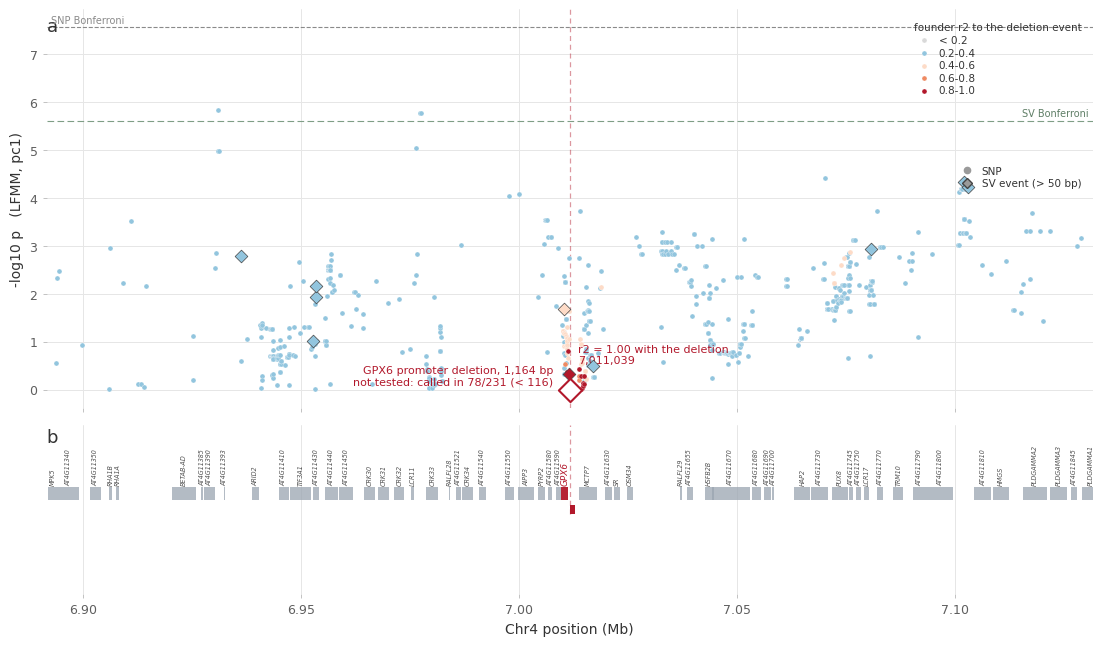

no SV event in the +-120 kb window clears the SV Bonferroni (5.60) on pc1: panel b marks only the GPX6 deletion
significant SVs marked in panel b:
Empty DataFrame
Columns: [sym, target_gene, placement, unit, pos, ref_len, alt_len, dlen, MAF, carriers, nlp, r2]
Index: []


In [5]:

draw_zoom(f"gpx6_ld_zoom_{AXIS_LD}_candidates", mark_candidates=True)
if not len(SVSIG):
    print(f"no SV event in the +-{HALF // 1000} kb window clears the SV Bonferroni ({BAR_SV:.2f}) on {AXIS_LD}: "
          "panel b marks only the GPX6 deletion")
print("significant SVs marked in panel b:")
print(SVSIG.sort_values("nlp", ascending=False)[["sym", "target_gene", "placement", "unit", "pos",
      "ref_len", "alt_len", "dlen", "MAF", "carriers", "nlp", "r2"]].round(4).to_string(index=False))
